# Titanic: Survival Rate by Age Group, Sex, and Class

This notebook loads the Seaborn Titanic dataset, adds age group columns, and calculates the percentage of passengers who survived within each group â€” broken down by **age group**, **sex**, and **class**. Each section includes a bar plot of the survival percentages.

## Load the dataset

In [43]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

df_titanic = sns.load_dataset("titanic")
df_titanic.head()

,survived,pclass,sex,age,sibsp,parch,fare,embarked,class,who,adult_male,deck,embark_town,alive,alone
0,0,3,male,22.0,1,0,7.2500,S,Third,man,True,NaN,Southampton,no,False
1,1,1,female,38.0,1,0,71.2833,C,First,woman,False,C,Cherbourg,yes,False
2,1,3,female,26.0,0,0,7.9250,S,Third,woman,False,NaN,Southampton,yes,True
3,1,1,female,35.0,1,0,53.1000,S,First,woman,False,C,Southampton,yes,False
4,0,3,male,35.0,0,0,8.0500,S,Third,man,True,NaN,Southampton,no,True


## Add age_group and age_label columns

Bin ages into groups using `pd.cut` and keep a string copy of each label in `age_label`.

In [44]:
boundaries = [-1, 12, 17, 21, 45, 100]
labels = ["child", "teen", "young adult", "middle age", "old person"]

df_titanic["age_group"] = pd.cut(df_titanic["age"], bins=boundaries, labels=labels)
df_titanic["age_label"] = df_titanic["age_group"].astype(str)

df_titanic[["age", "age_group", "age_label"]].head(10)

,age,age_group,age_label
0,22.0,middle age,middle age
1,38.0,middle age,middle age
2,26.0,middle age,middle age
3,35.0,middle age,middle age
4,35.0,middle age,middle age
5,NaN,NaN,nan
6,54.0,old person,old person
7,2.0,child,child
8,27.0,middle age,middle age
9,14.0,teen,teen


## Survival rate by age group

For each age group, compute the count of passengers and the percentage that survived.

In [45]:
age_summary = (
    df_titanic.groupby("age_group", observed=True)["survived"]
    .agg(["count", "mean"])
    .rename(columns={"count": "passengers", "mean": "survival_rate"})
)
age_summary["passengers"] = age_summary["passengers"].astype(int)
age_summary["survival_percent"] = (age_summary["survival_rate"] * 100).round(1)
age_summary = age_summary["survival_percent"].sort_values(ascending=False)

age_summary

age_group
child          58.0
teen           47.7
middle age     40.5
old person     36.9
young adult    28.6
Name: survival_percent, dtype: float64

### Bar plot: survival rate by age group

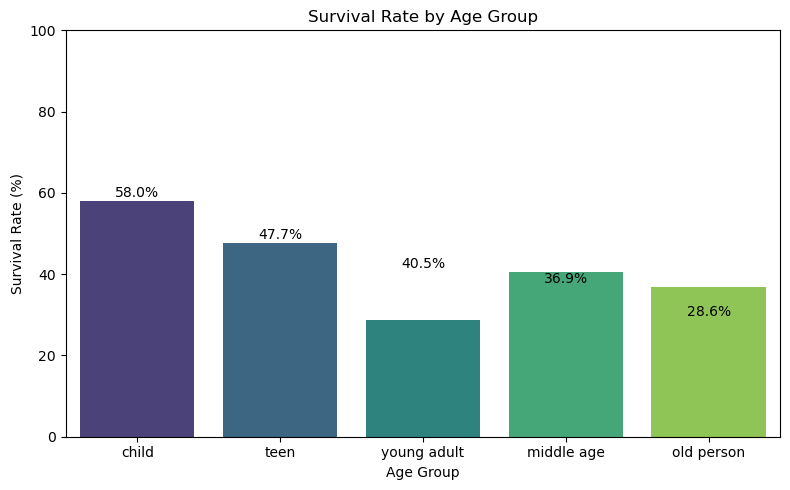

In [46]:
plt.figure(figsize=(8, 5))
ax = sns.barplot(x=age_summary.index, y=age_summary.values, palette="viridis")
ax.set_title("Survival Rate by Age Group")
ax.set_xlabel("Age Group")
ax.set_ylabel("Survival Rate (%)")
ax.set_ylim(0, 100)
for i, v in enumerate(age_summary.values):
    ax.text(i, v + 1, f"{v:.1f}%", ha="center")
plt.tight_layout()
plt.show()

## Survival rate by sex

In [47]:
sex_summary = (
    df_titanic.groupby("sex")["survived"]
    .mean()
    .mul(100)
    .round(1)
    .sort_values(ascending=False)
    .rename("survival_percent")
)

sex_summary

sex
female    74.2
male      18.9
Name: survival_percent, dtype: float64

### Bar plot: survival rate by sex

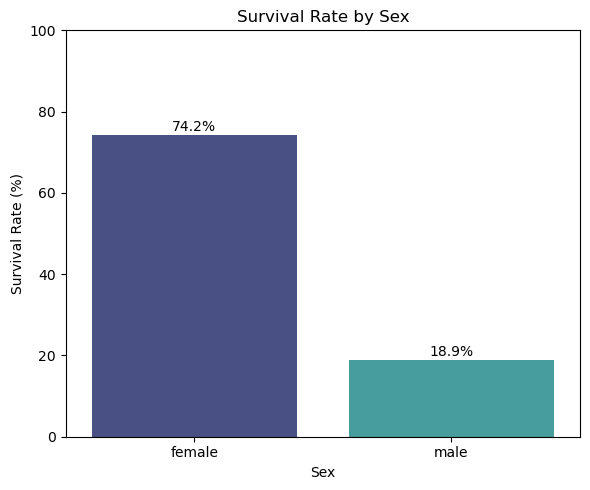

In [48]:
plt.figure(figsize=(6, 5))
ax = sns.barplot(x=sex_summary.index, y=sex_summary.values, palette="mako")
ax.set_title("Survival Rate by Sex")
ax.set_xlabel("Sex")
ax.set_ylabel("Survival Rate (%)")
ax.set_ylim(0, 100)
for i, v in enumerate(sex_summary.values):
    ax.text(i, v + 1, f"{v:.1f}%", ha="center")
plt.tight_layout()
plt.show()

## Survival rate by class

In [49]:
class_summary = (
    df_titanic.groupby("class")["survived"]
    .mean()
    .mul(100)
    .round(1)
    .sort_values(ascending=False)
    .rename("survival_percent")
)

class_summary

class
First     63.0
Second    47.3
Third     24.2
Name: survival_percent, dtype: float64

### Bar plot: survival rate by class

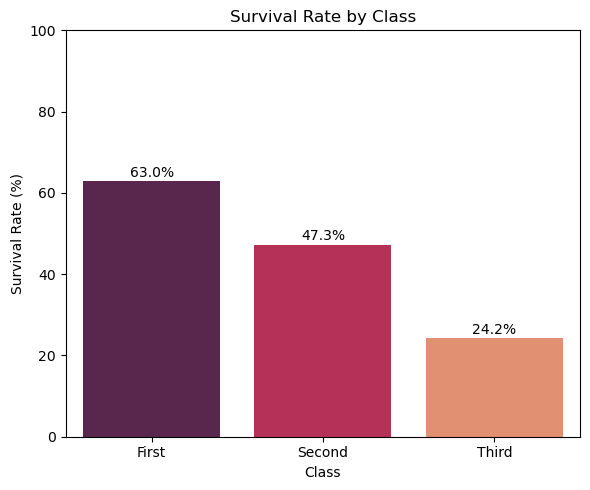

In [50]:
plt.figure(figsize=(6, 5))
ax = sns.barplot(x=class_summary.index, y=class_summary.values, palette="rocket")
ax.set_title("Survival Rate by Class")
ax.set_xlabel("Class")
ax.set_ylabel("Survival Rate (%)")
ax.set_ylim(0, 100)
for i, v in enumerate(class_summary.values):
    ax.text(i, v + 1, f"{v:.1f}%", ha="center")
plt.tight_layout()
plt.show()

## Survival rate by class and sex

Comparing men and women within each passenger class.

In [51]:
class_sex_summary = (
    df_titanic.groupby(["class", "sex"])["survived"]
    .mean()
    .mul(100)
    .round(1)
    .rename("survival_percent")
    .reset_index()
)

class_sex_summary

,class,sex,survival_percent
0,First,female,96.8
1,First,male,36.9
2,Second,female,92.1
3,Second,male,15.7
4,Third,female,50.0
5,Third,male,13.5


### Bar plot: survival rate by class and sex

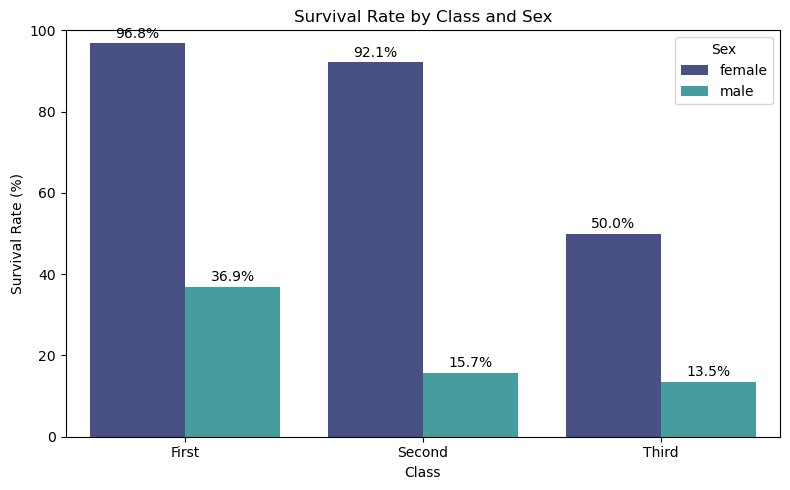

In [52]:
plt.figure(figsize=(8, 5))
ax = sns.barplot(
    data=class_sex_summary,
    x="class",
    y="survival_percent",
    hue="sex",
    palette="mako",
)
ax.set_title("Survival Rate by Class and Sex")
ax.set_xlabel("Class")
ax.set_ylabel("Survival Rate (%)")
ax.set_ylim(0, 100)
ax.legend(title="Sex")
for container in ax.containers:
    ax.bar_label(container, fmt="%.1f%%", padding=2)
plt.tight_layout()
plt.show()

## First class passengers who died, separated by gender

Filter first class passengers who did not survive, grouped by sex, with names where available.

In [ ]:
first_class_died = df_titanic[
    (df_titanic["class"] == "First") & (df_titanic["survived"] == 0)
].copy()

name_cols = [c for c in ["name"] if c in first_class_died.columns]
show_cols = name_cols + ["sex", "age"] if name_cols else ["sex", "age"]

for gender, group in first_class_died.groupby("sex"):
    print(f"\n=== {gender.capitalize()} who died in First class ({len(group)} passengers) ===")
    print(group[show_cols].to_string(index=False))

first_class_died

### Bar plot: first class deaths by gender

In [ ]:
gender_death_counts = first_class_died.groupby("sex").size()

plt.figure(figsize=(6, 5))
ax = sns.barplot(x=gender_death_counts.index, y=gender_death_counts.values, palette="mako")
ax.set_title("First Class Deaths by Gender")
ax.set_xlabel("Gender")
ax.set_ylabel("Number Who Died")
for i, v in enumerate(gender_death_counts.values):
    ax.text(i, v + 0.1, str(v), ha="center")
plt.tight_layout()
plt.show()